# Detección de spam en SMS con revisión humana de predicciones inciertas
**Grupo 03 · Sistemas Inteligentes y Machine Learning · Universidad Privada del Norte (Trujillo – San Isidro)**

Notebook experimental del artículo. Ejecuta el protocolo completo sobre el archivo oficial de UCI
*SMS Spam Collection* (DOI [10.24432/C5CC84](https://doi.org/10.24432/C5CC84)):

| Paso | Contenido | Datos que usa |
|---|---|---|
| 1–2 | Configuración, carga y diagnóstico del archivo oficial | todo el corpus (sólo descriptivo) |
| 3 | Partición 60/20/20 estratificada y agrupada por duplicados (semilla 42) | todo el corpus |
| 4 | Referencia de evaluación (clase mayoritaria) | entrenamiento → validación |
| 5–7 | Hiperparámetros por CV agrupada, diagnóstico de fuga, curvas de aprendizaje | sólo entrenamiento |
| 8–10 | Calibración, comparación de modelos y elección de τ | ajuste: entrenamiento · decisión: validación |
| 11 | **Congelamiento** de decisiones y persistencia del pipeline | — |
| 12–14 | Evaluación final única, análisis de errores y latencia | prueba |
| 15 | Figuras | resultados guardados |

**Regla de integridad:** la partición de prueba no se usa hasta la celda 12, después de escribir
`results/decisiones_congeladas.json`. Ninguna cifra del artículo debe tomarse de otra fuente que
no sea un archivo de `results/` generado por este notebook.

## 1. Configuración y entorno

In [1]:
import sys, os, json, time, platform, warnings, datetime as dt
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import sklearn, joblib, matplotlib
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold, cross_validate, learning_curve
from sklearn.metrics import brier_score_loss, log_loss, confusion_matrix
from sklearn.calibration import calibration_curve

from spam_sms.data import load_sms_collection, diagnose, grouped_stratified_split, group_key, sha256_of
from spam_sms.modeling import make_pipeline, make_calibrated_svm, PARAM_GRID, TOKEN_PATTERN, SEED
from spam_sms.decision import (TAU_GRID, decide, binary_metrics, selective_metrics, select_tau,
                               predict_label, confidence)

warnings.filterwarnings("ignore", category=FutureWarning)
DATA_ZIP = (ROOT.parent / "Dataset" / "sms+spam+collection.zip")
RES = ROOT / "results"; TAB = RES / "tablas"; FIG = RES / "figuras"; MOD = ROOT / "models"
for p in (RES, TAB, FIG, MOD):
    p.mkdir(parents=True, exist_ok=True)

def save_json(obj, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

entorno = {
    "fecha_ejecucion": dt.datetime.now().astimezone().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "plataforma": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos_logicos": os.cpu_count(),
    "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__, "matplotlib": matplotlib.__version__,
    "semilla": SEED,
}
save_json(entorno, RES / "entorno_ejecucion.json")
entorno

{'fecha_ejecucion': '2026-10-18T19:49:30-05:00',
 'python': '3.13.16',
 'plataforma': 'Linux-6.18.44-fc-v139-x86_64-with-glibc2.39',
 'procesador': 'x86_64',
 'nucleos_logicos': 2,
 'numpy': '2.5.3',
 'pandas': '3.0.5',
 'scikit-learn': '1.9.1',
 'joblib': '1.6.0',
 'matplotlib': '3.11.2',
 'semilla': 42}

## 2. Carga y diagnóstico del archivo oficial
Se lee el miembro `SMSSpamCollection` directamente del ZIP descargado de UCI. Se registra la huella
SHA-256 para que cualquier ejecución posterior pueda comprobar que usa el mismo archivo.
`csv.QUOTE_NONE` es obligatorio: con el comillado por defecto de pandas se pierden 2 filas (5572).

In [2]:
assert DATA_ZIP.exists(), f"No se encuentra {DATA_ZIP}"
huella = {"archivo": DATA_ZIP.name, "sha256_zip": sha256_of(DATA_ZIP), "bytes_zip": DATA_ZIP.stat().st_size}
df = load_sms_collection(DATA_ZIP)

# Comprobación de la decisión de lectura: comillado por defecto vs QUOTE_NONE
import zipfile, io
with zipfile.ZipFile(DATA_ZIP) as zf:
    raw = zf.read("SMSSpamCollection").decode("utf-8")
filas_comillado_defecto = len(pd.read_csv(io.StringIO(raw), sep="\t", header=None))
lineas_archivo = raw.count("\n")

diag = diagnose(df)
diag.update(huella)
diag["lineas_archivo"] = lineas_archivo
diag["filas_si_se_usa_comillado_por_defecto"] = filas_comillado_defecto
save_json(diag, RES / "diagnostico_dataset.json")
pd.Series(diag)

n_mensajes                                                                            5574
n_ham                                                                                 4827
n_spam                                                                                 747
pct_spam                                                                          0.134015
mensajes_vacios                                                                          0
filas_duplicadas_exactas                                                               403
textos_unicos_exactos                                                                 5171
filas_duplicadas_normalizadas                                                          415
grupos_normalizados                                                                   5159
textos_con_etiquetas_contradictorias                                                     0
grupos_normalizados_contradictorios                                                      0

In [3]:
dist = (df["label"].value_counts().rename("mensajes").to_frame()
          .assign(porcentaje=lambda t: 100 * t["mensajes"] / t["mensajes"].sum()))
uni = df.drop_duplicates("text")["label"].value_counts().rename("mensajes_unicos")
dist = dist.join(uni)
dist.to_csv(TAB / "distribucion_clases.csv")
dist.round(2)

,mensajes,porcentaje,mensajes_unicos
label,,,
ham,4827,86.6,4518
spam,747,13.4,653


In [4]:
# Indicadores textuales descriptivos (no se usan como variables del modelo)
ind = pd.DataFrame({
    "longitud_caracteres": df["text"].str.len(),
    "contiene_url": df["text"].str.contains(r"https?://|www\.|\.com\b", case=False, regex=True),
    "contiene_digitos_5mas": df["text"].str.contains(r"\d{5,}", regex=True),
    "contiene_moneda": df["text"].str.contains(r"[£$€]", regex=True),
    "label": df["label"],
})
resumen_ind = ind.groupby("label").agg(
    longitud_media=("longitud_caracteres", "mean"),
    longitud_mediana=("longitud_caracteres", "median"),
    pct_url=("contiene_url", "mean"),
    pct_digitos_5mas=("contiene_digitos_5mas", "mean"),
    pct_moneda=("contiene_moneda", "mean"),
)
for c in ["pct_url", "pct_digitos_5mas", "pct_moneda"]:
    resumen_ind[c] = 100 * resumen_ind[c]
resumen_ind.to_csv(TAB / "indicadores_textuales.csv")
resumen_ind.round(2)

,longitud_media,longitud_mediana,pct_url,pct_digitos_5mas,pct_moneda
label,,,,,
ham,71.47,52.0,0.29,0.06,0.39
spam,138.68,149.0,16.20,78.31,34.40


## 3. Partición 60/20/20 estratificada y agrupada por duplicados
Grupo = texto en minúsculas con espacios colapsados. `StratifiedGroupKFold(5)` separa la prueba;
sobre el resto, `StratifiedGroupKFold(4)` separa validación. Ningún grupo aparece en dos particiones.

In [5]:
idx_tr, idx_va, idx_te = grouped_stratified_split(df, seed=SEED)
df["grupo"] = df["text"].map(group_key)
split = pd.Series("entrenamiento", index=df.index)
split.iloc[idx_va] = "validacion"; split.iloc[idx_te] = "prueba"
df["particion"] = split.values
df[["particion", "label"]].reset_index().to_csv(RES / "particiones.csv", index=False)

tabla_part = (df.groupby("particion")["y"].agg(mensajes="size", spam="sum")
                .assign(ham=lambda t: t["mensajes"] - t["spam"],
                        pct_total=lambda t: 100 * t["mensajes"] / len(df),
                        pct_spam=lambda t: 100 * t["spam"] / t["mensajes"])
                .loc[["entrenamiento", "validacion", "prueba"]])
tabla_part["grupos_unicos"] = df.groupby("particion")["grupo"].nunique()
tabla_part.to_csv(TAB / "particiones_resumen.csv")
cruces = {a + "-" + b: len(set(df.loc[df.particion == a, "grupo"]) & set(df.loc[df.particion == b, "grupo"]))
          for a, b in [("entrenamiento", "validacion"), ("entrenamiento", "prueba"), ("validacion", "prueba")]}
print("Grupos compartidos entre particiones:", cruces)
tabla_part.round(2)

Grupos compartidos entre particiones: {'entrenamiento-validacion': 0, 'entrenamiento-prueba': 0, 'validacion-prueba': 0}


,mensajes,spam,ham,pct_total,pct_spam,grupos_unicos
particion,,,,,,
entrenamiento,3344,448,2896,59.99,13.40,3100
validacion,1115,149,966,20.00,13.36,1027
prueba,1115,150,965,20.00,13.45,1032


In [6]:
X = df["text"].to_numpy(); y = df["y"].to_numpy(); g = df["grupo"].to_numpy()
Xtr, ytr, gtr = X[idx_tr], y[idx_tr], g[idx_tr]
Xva, yva = X[idx_va], y[idx_va]
cv_tr = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits_tr = list(cv_tr.split(Xtr, ytr, gtr))   # mismos pliegues para todos los procedimientos internos
[len(te) for _, te in cv_splits_tr]

[669, 668, 669, 669, 669]

## 4. Referencia de evaluación (línea base)
Clasificador de clase mayoritaria (siempre *ham*). Sirve para mostrar que la *accuracy* por sí sola
es engañosa con 13.4 % de spam: alcanza ~87 % sin detectar ningún spam.

In [7]:
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
base_va = binary_metrics(yva, dummy.predict(Xva))
save_json(base_va, RES / "linea_base_validacion.json")
pd.Series(base_va)

n                 1115.000000
tp                   0.000000
fp                   0.000000
fn                 149.000000
tn                 966.000000
precision_spam       0.000000
recall_spam          0.000000
f1_spam              0.000000
precision_ham        0.866368
recall_ham           1.000000
f1_ham               0.928400
accuracy             0.866368
dtype: float64

## 5. Selección de hiperparámetros con validación cruzada agrupada (sólo entrenamiento)
Rejilla común: C ∈ {0.1, 1, 10} × n-gramas {(1,1), (1,2)}. Métrica de selección: F1 de spam.
El `TfidfVectorizer` está dentro del `Pipeline`, por lo que vocabulario e IDF se reajustan en cada pliegue.

In [8]:
scoring = {"f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy"}
busquedas, filas = {}, []
for alg in ["logreg", "linsvm"]:
    gs = GridSearchCV(make_pipeline(alg), PARAM_GRID, scoring=scoring, refit="f1",
                      cv=cv_splits_tr, n_jobs=1, return_train_score=True)
    t0 = time.perf_counter(); gs.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    busquedas[alg] = gs
    r = pd.DataFrame(gs.cv_results_)
    for _, row in r.iterrows():
        filas.append({
            "algoritmo": alg, "C": row["param_clf__C"], "ngramas": str(row["param_tfidf__ngram_range"]),
            "f1_cv_media": row["mean_test_f1"], "f1_cv_de": row["std_test_f1"],
            "precision_cv_media": row["mean_test_precision"], "recall_cv_media": row["mean_test_recall"],
            "accuracy_cv_media": row["mean_test_accuracy"], "f1_entrenamiento_media": row["mean_train_f1"],
            "rango": int(row["rank_test_f1"]),
        })
    print(alg, "mejor:", gs.best_params_, "F1 CV = %.4f" % gs.best_score_, "| tiempo búsqueda %.1f s" % t_fit)
cv_tabla = pd.DataFrame(filas)
cv_tabla.to_csv(TAB / "cv_rejilla.csv", index=False)
mejores = {alg: {"C": float(gs.best_params_["clf__C"]),
                 "ngram_range": list(gs.best_params_["tfidf__ngram_range"]),
                 "f1_cv": float(gs.best_score_)} for alg, gs in busquedas.items()}
save_json(mejores, RES / "mejores_hiperparametros.json")
cv_tabla.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_clas

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_clas

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


...

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


logreg mejor: {'clf__C': 10.0, 'tfidf__ngram_range': (1, 2)} F1 CV = 0.9484 | tiempo búsqueda 7.3 s


linsvm mejor: {'clf__C': 10.0, 'tfidf__ngram_range': (1, 2)} F1 CV = 0.9597 | tiempo búsqueda 4.5 s


,algoritmo,C,ngramas,f1_cv_media,f1_cv_de,precision_cv_media,recall_cv_media,accuracy_cv_media,f1_entrenamiento_media,rango
0,logreg,0.1,"(1, 1)",0.0000,0.0000,0.0000,0.0000,0.8660,0.0000,5
1,logreg,0.1,"(1, 2)",0.0000,0.0000,0.0000,0.0000,0.8660,0.0000,5
2,logreg,1.0,"(1, 1)",0.8684,0.0276,0.9971,0.7701,0.9689,0.8886,3
3,logreg,1.0,"(1, 2)",0.8325,0.0314,1.0000,0.7142,0.9617,0.8195,4
4,logreg,10.0,"(1, 1)",0.9428,0.0150,0.9855,0.9040,0.9853,0.9978,2
5,logreg,10.0,"(1, 2)",0.9484,0.0118,0.9976,0.9041,0.9868,0.9992,1
6,linsvm,0.1,"(1, 1)",0.8984,0.0127,0.9946,0.8193,0.9752,0.9205,5
7,linsvm,0.1,"(1, 2)",0.8678,0.0313,1.0000,0.7678,0.9689,0.8658,6
8,linsvm,1.0,"(1, 1)",0.9464,0.0149,0.9879,0.9085,0.9862,0.9980,3
9,linsvm,1.0,"(1, 2)",0.9571,0.0156,0.9928,0.9241,0.9889,1.0000,2


## 6. Diagnóstico de fuga por duplicados en la validación cruzada
Se repite la CV de la mejor configuración con `StratifiedKFold` **sin grupos** (duplicados pueden
caer en pliegues distintos) para cuantificar el optimismo que se evita con la partición agrupada.

In [9]:
fuga = []
for alg, b in mejores.items():
    est = make_pipeline(alg, C=b["C"], ngram_range=tuple(b["ngram_range"]))
    agr = cross_validate(est, Xtr, ytr, cv=cv_splits_tr, scoring=scoring)
    sin = cross_validate(est, Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring=scoring)
    for nombre, res in [("agrupada (StratifiedGroupKFold)", agr), ("sin agrupar (StratifiedKFold)", sin)]:
        fuga.append({"algoritmo": alg, "validacion_cruzada": nombre,
                     "f1_media": res["test_f1"].mean(), "f1_de": res["test_f1"].std(),
                     "precision_media": res["test_precision"].mean(), "recall_media": res["test_recall"].mean()})
fuga = pd.DataFrame(fuga); fuga.to_csv(TAB / "diagnostico_fuga_cv.csv", index=False)
fuga.round(4)

,algoritmo,validacion_cruzada,f1_media,f1_de,precision_media,recall_media
0,logreg,agrupada (StratifiedGroupKFold),0.9484,0.0118,0.9976,0.9041
1,logreg,sin agrupar (StratifiedKFold),0.9438,0.0118,0.9902,0.9018
2,linsvm,agrupada (StratifiedGroupKFold),0.9597,0.0128,0.9905,0.9308
3,linsvm,sin agrupar (StratifiedKFold),0.9597,0.0128,0.9882,0.9330


## 7. Curvas de aprendizaje (sólo entrenamiento, CV agrupada)

In [10]:
curvas = {}
tam = np.linspace(0.1, 1.0, 8)
for alg, b in mejores.items():
    est = make_pipeline(alg, C=b["C"], ngram_range=tuple(b["ngram_range"]))
    n, tr_s, te_s = learning_curve(est, Xtr, ytr, cv=cv_splits_tr, train_sizes=tam,
                                   scoring="f1", shuffle=True, random_state=SEED, n_jobs=1)
    curvas[alg] = pd.DataFrame({"n_entrenamiento": n,
                                "f1_entrenamiento_media": tr_s.mean(1), "f1_entrenamiento_de": tr_s.std(1),
                                "f1_cv_media": te_s.mean(1), "f1_cv_de": te_s.std(1)})
    curvas[alg].to_csv(TAB / f"curva_aprendizaje_{alg}.csv", index=False)
pd.concat(curvas, names=["algoritmo"]).round(4)

n_entrenamiento  f1_entrenamiento_media  f1_entrenamiento_de  \
algoritmo                                                                   
logreg    0              267                  1.0000               0.0000   
          1              611                  1.0000               0.0000   
          2              955                  1.0000               0.0000   
          3             1299                  1.0000               0.0000   
          4             1643                  0.9995               0.0010   
          5             1987                  0.9992               0.0010   
          6             2331                  0.9994               0.0008   
          7             2675                  0.9989               0.0010   
linsvm    0              267                  1.0000               0.0000   
          1              611                  1.0000               0.0000   
          2              955                  1.0000               0.0000   
          3             1299                  1.0000               0.0000   
          4             1643                  1.0000               0.0000   
          5             1987                  1.0000               0.0000   
          6             2331                  1.0000               0.0000   
          7             2675                  1.0000               0.0000   

             f1_cv_media  f1_cv_de  
algoritmo                           
logreg    0       0.5954    0.1569  
          1       0.8463    0.0518  
          2       0.8760    0.0357  
          3       0.9218    0.0133  
          4       0.9322    0.0130  
          5       0.9397    0.0158  
          6       0.9457    0.0138  
          7       0.9484    0.0118  
linsvm    0       0.8487    0.0373  
          1       0.9260    0.0207  
          2       0.9338    0.0143  
          3       0.9476    0.0151  
          4       0.9534    0.0138  
          5       0.9560    0.0083  
          6       0.9607    0.0095  
          7       0.9597    0.0128

## 8. Ajuste final en entrenamiento y calibración
* **Regresión logística:** probabilidades nativas; se reajusta el pipeline elegido sobre todo el entrenamiento.
* **SVM lineal:** no produce probabilidades. Se calibra con la sigmoide de Platt mediante
  `CalibratedClassifierCV` usando los **mismos 5 pliegues agrupados del entrenamiento**: cada SVM se ajusta en
  4 pliegues y su sigmoide en el pliegue excluido (no se reutilizan datos de ajuste para calibrar).
* La **validación** no interviene en ningún ajuste: sólo se usa para evaluar calibración y decidir.

In [11]:
modelos = {}
t0 = time.perf_counter()
b = mejores["logreg"]
modelos["logreg"] = make_pipeline("logreg", C=b["C"], ngram_range=tuple(b["ngram_range"])).fit(Xtr, ytr)
t_lr = time.perf_counter() - t0
t0 = time.perf_counter()
b = mejores["linsvm"]
modelos["linsvm"] = make_calibrated_svm(b["C"], tuple(b["ngram_range"]), cv_splits_tr).fit(Xtr, ytr)
t_svm = time.perf_counter() - t0
tiempos_ajuste = {"logreg_s": t_lr, "linsvm_calibrada_s": t_svm}
print(tiempos_ajuste)

def ece_top_label(y_true, p_spam, n_bins=10):
    conf = confidence(p_spam); pred = predict_label(p_spam)
    edges = np.linspace(0.5, 1.0, n_bins + 1); e = 0.0
    for i in range(n_bins):
        m = (conf >= edges[i]) & ((conf < edges[i + 1]) if i < n_bins - 1 else (conf <= edges[i + 1]))
        if m.any():
            e += m.mean() * abs((pred[m] == y_true[m]).mean() - conf[m].mean())
    return float(e)

p_va = {alg: m.predict_proba(Xva)[:, 1] for alg, m in modelos.items()}
cal = []
for alg, p in p_va.items():
    cal.append({"algoritmo": alg, "brier": brier_score_loss(yva, p), "log_loss": log_loss(yva, p, labels=[0, 1]),
                "ece_top_label_10": ece_top_label(yva, p)})
    bins = np.minimum((p * 10).astype(int), 9)
    rel = (pd.DataFrame({"bin": bins, "p": p, "y": yva}).groupby("bin")
             .agg(prob_media_predicha=("p", "mean"), frecuencia_spam_observada=("y", "mean"), n=("y", "size"))
             .reset_index())
    rel.to_csv(TAB / f"fiabilidad_validacion_{alg}.csv", index=False)
cal = pd.DataFrame(cal); cal.to_csv(TAB / "calibracion_validacion.csv", index=False)
cal.round(4)

{'logreg_s': 0.41926236299991615, 'linsvm_calibrada_s': 0.6925544289999834}


,algoritmo,brier,log_loss,ece_top_label_10
0,logreg,0.0151,0.0660,0.0225
1,linsvm,0.0099,0.0406,0.0069


## 9. Comparación de modelos en validación y regla de selección (preregistrada)
Regla fijada antes de ejecutar: se elige el mayor **F1 de spam en validación** (umbral 0.5, sin abstención).
Si la diferencia es < 0.005, se elige el menor **Brier**; si persiste el empate, la regresión logística.

In [12]:
comp = []
for alg, p in p_va.items():
    m = binary_metrics(yva, predict_label(p)); m["algoritmo"] = alg
    m["brier"] = float(cal.set_index("algoritmo").loc[alg, "brier"])
    comp.append(m)
comp = pd.DataFrame(comp).set_index("algoritmo")
comp.to_csv(TAB / "comparacion_validacion.csv")

f1_lr, f1_svm = comp.loc["logreg", "f1_spam"], comp.loc["linsvm", "f1_spam"]
if abs(f1_lr - f1_svm) >= 0.005:
    elegido = "logreg" if f1_lr > f1_svm else "linsvm"; motivo = "mayor F1 de spam en validación"
elif comp.loc["logreg", "brier"] != comp.loc["linsvm", "brier"]:
    elegido = comp["brier"].idxmin(); motivo = "F1 equivalente (|Δ| < 0.005); menor Brier"
else:
    elegido = "logreg"; motivo = "empate total; se prefiere la regresión logística"
print("Modelo elegido:", elegido, "-", motivo)
comp[["n", "tp", "fp", "fn", "tn", "precision_spam", "recall_spam", "f1_spam", "accuracy", "brier"]].round(4)

Modelo elegido: linsvm - mayor F1 de spam en validación


,n,tp,fp,fn,tn,precision_spam,recall_spam,f1_spam,accuracy,brier
algoritmo,,,,,,,,,,
logreg,1115,129,2,20,964,0.9847,0.8658,0.9214,0.9803,0.0151
linsvm,1115,136,2,13,964,0.9855,0.9128,0.9477,0.9865,0.0099


## 10. Umbral de revisión τ en validación (regla preregistrada)
Para cada τ ∈ {0.50, 0.60, 0.70, 0.80, 0.90, 0.95}: confianza c = max(p₀, p₁); si c < τ → revisión.
Se elige el τ de **mayor cobertura** cuyo **error entre aceptados ≤ 1.0 %** y **tasa de revisión ≤ 15 %**
(empate → menor τ). Si ninguno cumple: menor error entre aceptados con revisión ≤ 15 %.

In [13]:
sel_va = {alg: pd.DataFrame([selective_metrics(yva, p, t) for t in TAU_GRID]) for alg, p in p_va.items()}
for alg, t in sel_va.items():
    t.to_csv(TAB / f"umbrales_validacion_{alg}.csv", index=False)
eleccion_tau = select_tau(sel_va[elegido].to_dict("records"))
print("τ elegido:", eleccion_tau)
cols = ["tau", "n_aceptados", "n_revision", "cobertura", "tasa_revision", "errores_aceptados", "error_aceptados",
        "acc_precision_spam", "acc_recall_spam", "acc_f1_spam"]
pd.concat({a: t[cols] for a, t in sel_va.items()}, names=["algoritmo"]).round(4)

τ elegido: {'tau': 0.7, 'factible': True}


tau  n_aceptados  n_revision  cobertura  tasa_revision  \
algoritmo                                                              
logreg    0  0.50         1115           0     1.0000         0.0000   
          1  0.60         1106           9     0.9919         0.0081   
          2  0.70         1094          21     0.9812         0.0188   
          3  0.80         1075          40     0.9641         0.0359   
          4  0.90         1024          91     0.9184         0.0816   
          5  0.95          930         185     0.8341         0.1659   
linsvm    0  0.50         1115           0     1.0000         0.0000   
          1  0.60         1111           4     0.9964         0.0036   
          2  0.70         1108           7     0.9937         0.0063   
          3  0.80         1097          18     0.9839         0.0161   
          4  0.90         1077          38     0.9659         0.0341   
          5  0.95         1042          73     0.9345         0.0655   

             errores_aceptados  error_aceptados  acc_precision_spam  \
algoritmo                                                             
logreg    0                 22           0.0197              0.9847   
          1                 15           0.0136              0.9845   
          2                 12           0.0110              0.9836   
          3                  8           0.0074              0.9907   
          4                  6           0.0059              0.9885   
          5                  1           0.0011              1.0000   
linsvm    0                 15           0.0135              0.9855   
          1                 12           0.0108              0.9855   
          2                 10           0.0090              0.9926   
          3                  8           0.0073              0.9923   
          4                  5           0.0046              1.0000   
          5                  3           0.0029              1.0000   

             acc_recall_spam  acc_f1_spam  
algoritmo                                  
logreg    0           0.8658       0.9214  
          1           0.9071       0.9442  
          2           0.9231       0.9524  
          3           0.9386       0.9640  
          4           0.9451       0.9663  
          5           0.9818       0.9908  
linsvm    0           0.9128       0.9477  
          1           0.9315       0.9577  
          2           0.9375       0.9643  
          3           0.9485       0.9699  
          4           0.9606       0.9799  
          5           0.9735       0.9865

## 11. Congelamiento de decisiones y persistencia
Se guarda el modelo elegido **entrenado sólo con entrenamiento** y un registro de las decisiones.
A partir de aquí no se modifica ninguna decisión.

In [14]:
modelo_final = modelos[elegido]
artefacto = {"modelo": modelo_final, "tau": eleccion_tau["tau"], "algoritmo": elegido,
             "hiperparametros": mejores[elegido], "token_pattern": TOKEN_PATTERN,
             "etiquetas": {"0": "legitimo (ham)", "1": "spam"}, "version": "v1"}
ruta_modelo = MOD / "modelo_spam_v1.joblib"
joblib.dump(artefacto, ruta_modelo)
congeladas = {
    "fecha_congelamiento": dt.datetime.now().astimezone().isoformat(timespec="seconds"),
    "modelo_elegido": elegido, "motivo": motivo, "hiperparametros": mejores[elegido],
    "calibracion": "probabilidades nativas" if elegido == "logreg" else "sigmoide (Platt), CV agrupada 5 pliegues en entrenamiento",
    "tau": eleccion_tau["tau"], "tau_factible_en_validacion": eleccion_tau["factible"],
    "criterio_tau": "max cobertura con error_aceptados<=0.010 y tasa_revision<=0.15 (validación)",
    "metas_preregistradas_prueba": {"f1_spam_min": 0.90, "precision_spam_min": 0.95},
    "ruta_modelo": str(ruta_modelo.relative_to(ROOT)), "sha256_modelo": sha256_of(ruta_modelo),
}
save_json(congeladas, RES / "decisiones_congeladas.json")
congeladas

{'fecha_congelamiento': '2026-10-18T19:50:08-05:00',
 'modelo_elegido': 'linsvm',
 'motivo': 'mayor F1 de spam en validación',
 'hiperparametros': {'C': 10.0,
  'ngram_range': [1, 2],
  'f1_cv': 0.9596675310627243},
 'calibracion': 'sigmoide (Platt), CV agrupada 5 pliegues en entrenamiento',
 'tau': 0.7,
 'tau_factible_en_validacion': True,
 'criterio_tau': 'max cobertura con error_aceptados<=0.010 y tasa_revision<=0.15 (validación)',
 'metas_preregistradas_prueba': {'f1_spam_min': 0.9,
  'precision_spam_min': 0.95},
 'ruta_modelo': 'models/modelo_spam_v1.joblib',
 'sha256_modelo': 'de87978042e6c821cb8a4fb2dff3cee4ada58ac3ff1ef65ef0ea703e55482705'}

## 12. Evaluación final en la partición de prueba (una sola vez)
Se carga el artefacto congelado desde disco y se evalúa. Los intervalos de confianza son percentiles
de 2000 remuestreos *bootstrap* de los mensajes de prueba (semilla 42).

In [15]:
art = joblib.load(ruta_modelo)
Xte, yte = X[idx_te], y[idx_te]
p_te = art["modelo"].predict_proba(Xte)[:, 1]
yhat_te = predict_label(p_te)
final = binary_metrics(yte, yhat_te)

rng = np.random.default_rng(SEED); B = 2000; boot = {k: [] for k in ["precision_spam", "recall_spam", "f1_spam", "accuracy"]}
for _ in range(B):
    s = rng.integers(0, len(yte), len(yte)); m = binary_metrics(yte[s], yhat_te[s])
    for k in boot: boot[k].append(m[k])
ic = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in boot.items()}
final["ic95_bootstrap"] = ic
final["brier"] = float(brier_score_loss(yte, p_te)); final["ece_top_label_10"] = ece_top_label(yte, p_te)
final["linea_base_prueba"] = binary_metrics(yte, dummy.predict(Xte))
final["metas"] = {"f1_spam>=0.90": final["f1_spam"] >= 0.90, "precision_spam>=0.95": final["precision_spam"] >= 0.95}

tau = art["tau"]
final["selectiva_tau_elegido"] = selective_metrics(yte, p_te, tau)
sel_te = pd.DataFrame([selective_metrics(yte, p_te, t) for t in TAU_GRID])
sel_te.to_csv(TAB / "umbrales_prueba_descriptivo.csv", index=False)

# Revisión humana IDEAL SIMULADA: el revisor asigna la etiqueta del dataset (cota optimista, no es prueba con usuarios)
yhat_sys, acc = decide(p_te, tau)
y_sistema = np.where(acc, yhat_sys, yte)
final["sistema_con_revision_ideal_simulada"] = binary_metrics(yte, y_sistema)

# Sensibilidad: prueba sin duplicados internos (primer ejemplar de cada grupo)
te_df = df.iloc[idx_te].assign(p=p_te)
uniq = ~te_df["grupo"].duplicated()
final["prueba_sin_duplicados"] = binary_metrics(te_df.loc[uniq, "y"].to_numpy(), predict_label(te_df.loc[uniq, "p"].to_numpy()))
save_json(final, RES / "evaluacion_final_prueba.json")
print(json.dumps({k: final[k] for k in ["tp", "fp", "fn", "tn", "precision_spam", "recall_spam", "f1_spam", "accuracy", "metas"]}, indent=1))
final["selectiva_tau_elegido"]

{
 "tp": 137,
 "fp": 2,
 "fn": 13,
 "tn": 963,
 "precision_spam": 0.9856115107913669,
 "recall_spam": 0.9133333333333333,
 "f1_spam": 0.9480968858131488,
 "accuracy": 0.9865470852017937,
 "metas": {
  "f1_spam>=0.90": true,
  "precision_spam>=0.95": true
 }
}


{'tau': 0.7,
 'n_total': 1115,
 'n_aceptados': 1109,
 'n_revision': 6,
 'cobertura': 0.9946188340807175,
 'tasa_revision': 0.0053811659192825115,
 'aceptados_ham': 962,
 'aceptados_spam': 147,
 'revision_ham': 3,
 'revision_spam': 3,
 'errores_aceptados': 11,
 'errores_en_revision_si_automatico': 4,
 'error_aceptados': 0.009918845807033363,
 'acc_n': 1109,
 'acc_tp': 136,
 'acc_fp': 0,
 'acc_fn': 11,
 'acc_tn': 962,
 'acc_precision_spam': 1.0,
 'acc_recall_spam': 0.9251700680272109,
 'acc_f1_spam': 0.9611307420494699,
 'acc_precision_ham': 0.9886947584789312,
 'acc_recall_ham': 1.0,
 'acc_f1_ham': 0.9943152454780362,
 'acc_accuracy': 0.9900811541929666}

## 13. Análisis de errores en prueba

In [16]:
te_df["y_hat"] = yhat_te; te_df["confianza"] = confidence(p_te); te_df["aceptado"] = acc
err = te_df[te_df["y"] != te_df["y_hat"]].copy()
err["tipo"] = np.where(err["y"] == 0, "falso positivo (ham→spam)", "falso negativo (spam→ham)")
err["longitud"] = err["text"].str.len()
err["contiene_url"] = err["text"].str.contains(r"https?://|www\.|\.com\b", case=False, regex=True)
err["contiene_digitos_5mas"] = err["text"].str.contains(r"\d{5,}", regex=True)
err["destino_con_tau"] = np.where(err["aceptado"], "decisión automática (error no detectado)", "enviado a revisión")
err = err.sort_values(["tipo", "p"])
err[["tipo", "p", "confianza", "destino_con_tau", "longitud", "contiene_url", "contiene_digitos_5mas", "text"]].to_csv(
    TAB / "errores_prueba.csv", index_label="msg_id")
pd.set_option("display.max_colwidth", 70)
err[["tipo", "p", "destino_con_tau", "longitud", "text"]]

,tipo,p,destino_con_tau,longitud,text
msg_id,,,,,
4514,falso negativo (spam→ham),0.001468,decisión automática (error no detectado),51,Money i have won wining number 946 wot do i do next
869,falso negativo (spam→ham),0.002075,decisión automática (error no detectado),134,Hello. We need some posh birds and chaps to user trial prods for c...
751,falso negativo (spam→ham),0.002202,decisión automática (error no detectado),102,"Do you realize that in about 40 years, we'll have thousands of old..."
68,falso negativo (spam→ham),0.009173,decisión automática (error no detectado),78,"Did you hear about the new ""Divorce Barbie""? It comes with all of ..."
3460,falso negativo (spam→ham),0.011260,decisión automática (error no detectado),153,Not heard from U4 a while. Call me now am here all night with just...
3419,falso negativo (spam→ham),0.014246,decisión automática (error no detectado),136,LIFE has never been this much fun and great until you came in. You...
2247,falso negativo (spam→ham),0.015827,decisión automática (error no detectado),181,Hi ya babe x u 4goten bout me?' scammers getting smart..Though thi...
731,falso negativo (spam→ham),0.151908,decisión automática (error no detectado),101,Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripit...
955,falso negativo (spam→ham),0.193066,decisión automática (error no detectado),41,Filthy stories and GIRLS waiting for your


## 14. Latencia de inferencia (hardware del entorno de ejecución)

In [17]:
muestras = Xte[:300]; tiempos = []
for s in muestras:
    t0 = time.perf_counter(); art["modelo"].predict_proba([s]); tiempos.append(1000 * (time.perf_counter() - t0))
lat = {"mediana_ms": float(np.median(tiempos)), "p95_ms": float(np.percentile(tiempos, 95)), "n": len(tiempos),
       "tiempo_ajuste_s": tiempos_ajuste}
save_json(lat, RES / "latencia_inferencia.json"); lat

{'mediana_ms': 5.891895999980079,
 'p95_ms': 8.556592750107939,
 'n': 300,
 'tiempo_ajuste_s': {'logreg_s': 0.41926236299991615,
  'linsvm_calibrada_s': 0.6925544289999834}}

## 15. Figuras del artículo (datos reales de este notebook)
Colores fijos: ham = azul `#2a78d6`, spam = naranja `#eb6834`; regresión logística = violeta `#6250d6`,
SVM lineal = aguamarina `#1baf7a`; revisión = gris. Paleta validada para daltonismo.

In [18]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
fuentes = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "font.family": "EB Garamond" if "EB Garamond" in fuentes else "serif",
    "font.size": 10, "axes.titlesize": 10.5, "axes.labelsize": 10, "legend.fontsize": 9,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "savefig.dpi": 300, "savefig.bbox": "tight", "figure.dpi": 110,
})
C_HAM, C_SPAM, C_LR, C_SVM, C_REV, INK2 = "#2a78d6", "#eb6834", "#6250d6", "#1baf7a", "#8a8984", "#52514e"
NOMBRE = {"logreg": "Regresión logística", "linsvm": "SVM lineal (calibrada)"}
def guardar(fig, nombre):
    for ext in ("png", "svg"):
        fig.savefig(FIG / f"{nombre}.{ext}")
    plt.show()

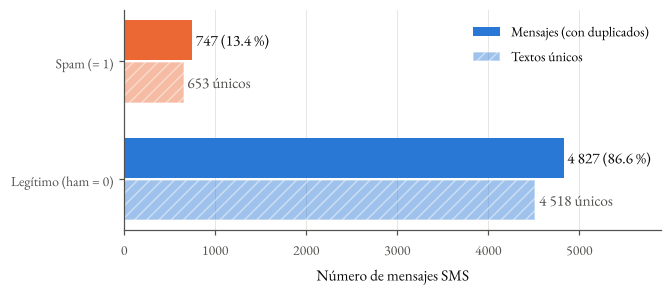

In [19]:
# Figura: distribución de clases (total y únicos)
fig, ax = plt.subplots(figsize=(6.3, 2.6))
cats = ["Legítimo (ham = 0)", "Spam (= 1)"]
tot = [diag["n_ham"], diag["n_spam"]]; unq = [diag["unicos_ham"], diag["unicos_spam"]]
ypos = np.arange(2)
ax.barh(ypos + 0.18, tot, height=0.34, color=[C_HAM, C_SPAM], label="Mensajes (con duplicados)")
ax.barh(ypos - 0.18, unq, height=0.34, color=[C_HAM, C_SPAM], alpha=0.45, hatch="///", edgecolor="white",
        label="Textos únicos")
for i in range(2):
    ax.text(tot[i] + 40, i + 0.18, f"{tot[i]:,} ({100*tot[i]/diag['n_mensajes']:.1f} %)".replace(",", " "), va="center", color="#0b0b0b")
    ax.text(unq[i] + 40, i - 0.18, f"{unq[i]:,} únicos".replace(",", " "), va="center", color=INK2)
ax.set_yticks(ypos, cats); ax.set_xlabel("Número de mensajes SMS"); ax.set_xlim(0, 5900)
ax.grid(axis="y", visible=False); ax.legend(loc="upper right", frameon=False)
guardar(fig, "fig_distribucion_clases")

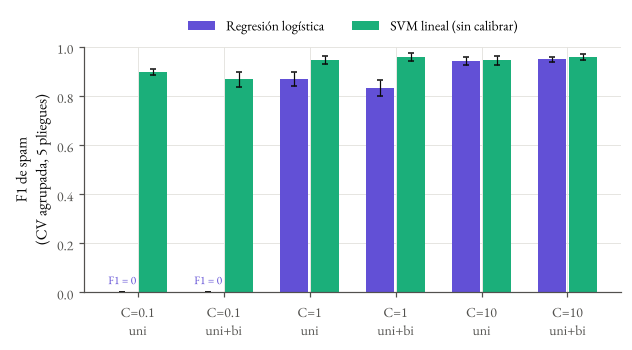

In [20]:
# Figura: comparación de configuraciones en CV agrupada (F1 de spam, media ± DE)
fig, ax = plt.subplots(figsize=(6.3, 2.9))
etq = [f"C={c:g}\n{'uni' if n=='(1, 1)' else 'uni+bi'}" for c, n in
       cv_tabla.loc[cv_tabla.algoritmo == "logreg", ["C", "ngramas"]].itertuples(index=False)]
xpos = np.arange(len(etq)); w = 0.36
for k, (alg, col) in enumerate([("logreg", C_LR), ("linsvm", C_SVM)]):
    t = cv_tabla[cv_tabla.algoritmo == alg]
    ax.bar(xpos + (k - 0.5) * w, t["f1_cv_media"], width=w - 0.04, yerr=t["f1_cv_de"], color=col,
           error_kw={"elinewidth": 0.8, "capsize": 2, "ecolor": "#0b0b0b"},
           label=NOMBRE[alg].replace(" (calibrada)", " (sin calibrar)"))
t = cv_tabla[cv_tabla.algoritmo == "logreg"].reset_index(drop=True)
for i, v in enumerate(t["f1_cv_media"]):
    if v == 0:
        ax.text(xpos[i] - 0.5 * w, 0.02, "F1 = 0", ha="center", va="bottom", fontsize=7.5, color=C_LR)
ax.set_xticks(xpos, etq); ax.set_ylabel("F1 de spam\n(CV agrupada, 5 pliegues)")
ax.set_ylim(0, 1.0); ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
guardar(fig, "fig_comparacion_cv")

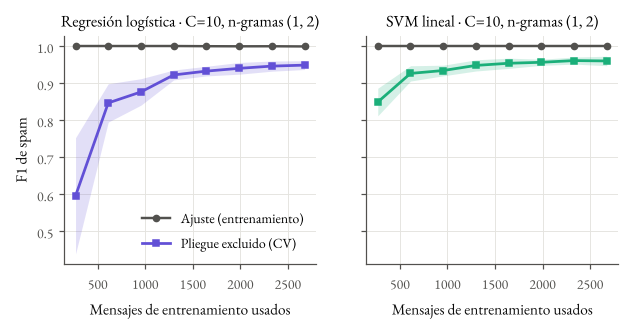

In [21]:
# Figura: curvas de aprendizaje
fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.7), sharey=True)
for ax, alg in zip(axs, ["logreg", "linsvm"]):
    c = curvas[alg]
    ax.plot(c.n_entrenamiento, c.f1_entrenamiento_media, "-o", color=INK2, lw=1.6, ms=4, label="Ajuste (entrenamiento)")
    ax.fill_between(c.n_entrenamiento, c.f1_cv_media - c.f1_cv_de, c.f1_cv_media + c.f1_cv_de,
                    color=C_LR if alg == "logreg" else C_SVM, alpha=0.18, lw=0)
    ax.plot(c.n_entrenamiento, c.f1_cv_media, "-s", color=C_LR if alg == "logreg" else C_SVM, lw=1.8, ms=4,
            label="Pliegue excluido (CV)")
    b = mejores[alg]
    ax.set_title(f"{NOMBRE[alg].replace(' (calibrada)', '')} · C={b['C']:g}, n-gramas {tuple(b['ngram_range'])}")
    ax.set_xlabel("Mensajes de entrenamiento usados")
axs[0].set_ylabel("F1 de spam"); axs[0].legend(frameon=False, loc="lower right")
guardar(fig, "fig_curvas_aprendizaje")

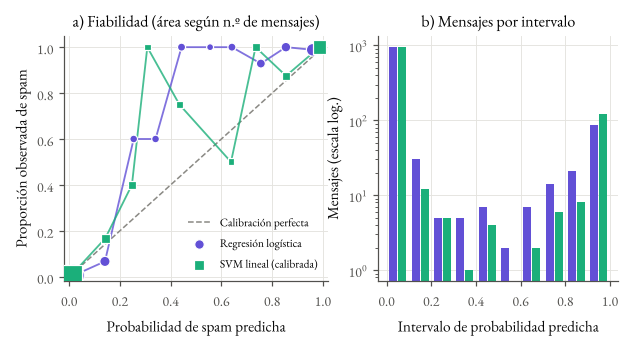

In [22]:
# Figura: diagrama de fiabilidad (validación) + número de mensajes por intervalo
fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.9), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axs[0]
ax.plot([0, 1], [0, 1], ls="--", color=C_REV, lw=1, label="Calibración perfecta")
for alg, col, mk in [("logreg", C_LR, "o"), ("linsvm", C_SVM, "s")]:
    t = pd.read_csv(TAB / f"fiabilidad_validacion_{alg}.csv")
    ax.plot(t.prob_media_predicha, t.frecuencia_spam_observada, color=col, lw=1.2, alpha=0.8)
    ax.scatter(t.prob_media_predicha, t.frecuencia_spam_observada, s=12 + 6 * np.sqrt(t.n), marker=mk, color=col,
               edgecolor="white", linewidth=0.8, zorder=3, label=NOMBRE[alg])
ax.set_xlabel("Probabilidad de spam predicha"); ax.set_ylabel("Proporción observada de spam")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.05); ax.legend(frameon=False, loc="lower right", fontsize=7.5, markerscale=0.6)
ax.set_title("a) Fiabilidad (área según n.º de mensajes)")
ax = axs[1]; w2 = 0.04
for k, (alg, col) in enumerate([("logreg", C_LR), ("linsvm", C_SVM)]):
    t = pd.read_csv(TAB / f"fiabilidad_validacion_{alg}.csv")
    ax.bar(t["bin"] / 10 + 0.05 + (k - 0.5) * w2, t.n, width=w2 - 0.004, color=col, label=NOMBRE[alg])
ax.set_yscale("log"); ax.set_xlabel("Intervalo de probabilidad predicha"); ax.set_ylabel("Mensajes (escala log.)")
ax.set_xticks(np.linspace(0, 1, 6)); ax.set_title("b) Mensajes por intervalo")
guardar(fig, "fig_fiabilidad_validacion")

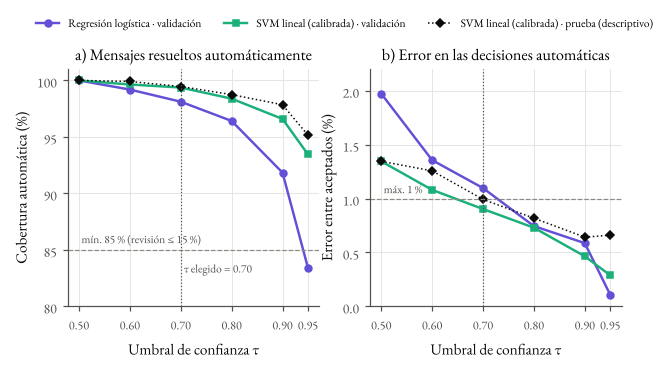

In [23]:
# Figura: cobertura automática y error entre aceptados según τ (validación = selección; prueba = descriptivo)
fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.8))
for alg, col, mk in [("logreg", C_LR, "o"), ("linsvm", C_SVM, "s")]:
    t = sel_va[alg]
    axs[0].plot(t.tau, 100 * t.cobertura, marker=mk, color=col, lw=1.6, ms=4.5, label=f"{NOMBRE[alg]} · validación")
    axs[1].plot(t.tau, 100 * t.error_aceptados, marker=mk, color=col, lw=1.6, ms=4.5, label=f"{NOMBRE[alg]} · validación")
axs[0].plot(sel_te.tau, 100 * sel_te.cobertura, marker="D", color="#0b0b0b", lw=1.0, ls=":", ms=3.5,
            label=f"{NOMBRE[elegido]} · prueba (descriptivo)")
axs[1].plot(sel_te.tau, 100 * sel_te.error_aceptados, marker="D", color="#0b0b0b", lw=1.0, ls=":", ms=3.5)
axs[0].axhline(85, color=C_REV, lw=0.8, ls="--"); axs[0].text(0.505, 85.6, "mín. 85 % (revisión ≤ 15 %)", fontsize=7.5, color=INK2)
axs[1].axhline(1.0, color=C_REV, lw=0.8, ls="--"); axs[1].text(0.505, 1.05, "máx. 1 %", fontsize=7.5, color=INK2)
for ax in axs:
    ax.axvline(tau, color=INK2, lw=0.8, ls=":"); ax.set_xlabel("Umbral de confianza τ"); ax.set_xticks(TAU_GRID)
    ax.tick_params(axis="x", labelsize=8)
axs[0].text(tau + 0.006, 83.0, f"τ elegido = {tau:.2f}", fontsize=7.5, color=INK2)
axs[0].set_ylabel("Cobertura automática (%)"); axs[0].set_ylim(80, 101); axs[0].set_title("a) Mensajes resueltos automáticamente")
axs[1].set_ylabel("Error entre aceptados (%)"); axs[1].set_ylim(0, 2.2); axs[1].set_title("b) Error en las decisiones automáticas")
axs[0].legend(frameon=False, fontsize=7.5, loc="lower center", bbox_to_anchor=(1.1, 1.12), ncol=3)
guardar(fig, "fig_cobertura_error")

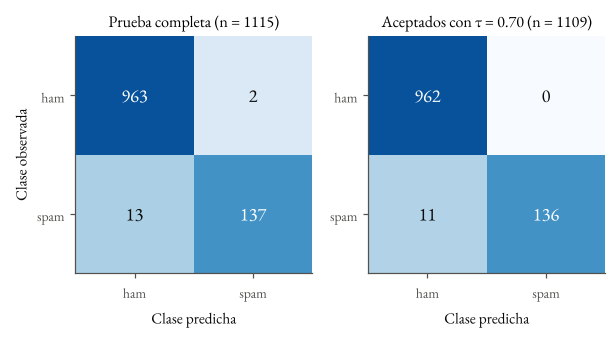

In [24]:
# Figura: matrices de confusión en prueba (cobertura total y subconjunto aceptado con τ elegido)
fig, axs = plt.subplots(1, 2, figsize=(6.3, 2.8))
cm_total = confusion_matrix(yte, yhat_te, labels=[0, 1])
cm_acc = confusion_matrix(yte[acc], yhat_te[acc], labels=[0, 1])
tit = [f"Prueba completa (n = {len(yte)})", f"Aceptados con τ = {tau:.2f} (n = {int(acc.sum())})"]
for ax, cm, t in zip(axs, [cm_total, cm_acc], tit):
    ax.imshow(np.log1p(cm), cmap="Blues", vmin=0, vmax=np.log1p(cm_total.max()) * 1.15)
    for i in range(2):
        for j in range(2):
            v = cm[i, j]; claro = np.log1p(v) > 0.6 * np.log1p(cm_total.max())
            ax.text(j, i, f"{v}", ha="center", va="center", fontsize=12, color="white" if claro else "#0b0b0b")
    ax.set_xticks([0, 1], ["ham", "spam"]); ax.set_yticks([0, 1], ["ham", "spam"])
    ax.set_xlabel("Clase predicha"); ax.set_title(t); ax.grid(False)
axs[0].set_ylabel("Clase observada")
guardar(fig, "fig_matrices_confusion")

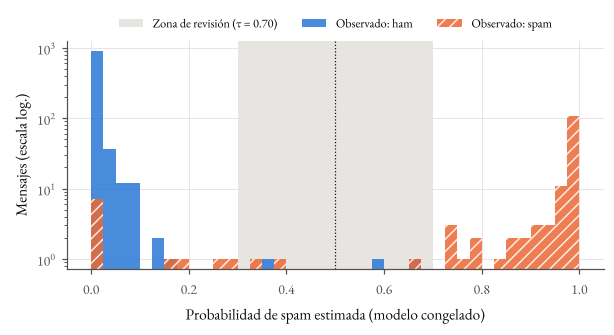

In [25]:
# Figura: distribución de P(spam) en prueba por clase observada, con la zona de revisión del τ elegido
fig, ax = plt.subplots(figsize=(6.3, 2.7))
bins_h = np.linspace(0, 1, 41)
ax.axvspan(1 - tau, tau, color="#e4e3df", alpha=0.9, lw=0, label=f"Zona de revisión (τ = {tau:.2f})")
ax.hist(p_te[yte == 0], bins=bins_h, color=C_HAM, alpha=0.85, label="Observado: ham")
ax.hist(p_te[yte == 1], bins=bins_h, color=C_SPAM, alpha=0.85, label="Observado: spam", hatch="///", edgecolor="white", linewidth=0)
ax.axvline(0.5, color="#0b0b0b", lw=0.8, ls=":")
ax.set_yscale("log"); ax.set_xlabel("Probabilidad de spam estimada (modelo congelado)"); ax.set_ylabel("Mensajes (escala log.)")
ax.legend(frameon=False, fontsize=8, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.16))
guardar(fig, "fig_distribucion_probabilidades_prueba")

## 16. Archivos generados

In [26]:
sorted(str(p.relative_to(ROOT)) for p in list(RES.rglob("*.*")) + list(MOD.glob("*.joblib")))

['models/modelo_spam_v1.joblib',
 'results/decisiones_congeladas.json',
 'results/diagnostico_dataset.json',
 'results/entorno_ejecucion.json',
 'results/evaluacion_final_prueba.json',
 'results/figuras/fig_cobertura_error.png',
 'results/figuras/fig_cobertura_error.svg',
 'results/figuras/fig_comparacion_cv.png',
 'results/figuras/fig_comparacion_cv.svg',
 'results/figuras/fig_curvas_aprendizaje.png',
 'results/figuras/fig_curvas_aprendizaje.svg',
 'results/figuras/fig_distribucion_clases.png',
 'results/figuras/fig_distribucion_clases.svg',
 'results/figuras/fig_distribucion_probabilidades_prueba.png',
 'results/figuras/fig_distribucion_probabilidades_prueba.svg',
 'results/figuras/fig_fiabilidad_validacion.png',
 'results/figuras/fig_fiabilidad_validacion.svg',
 'results/figuras/fig_matrices_confusion.png',
 'results/figuras/fig_matrices_confusion.svg',
 'results/latencia_inferencia.json',
 'results/linea_base_validacion.json',
 'results/mejores_hiperparametros.json',
 'results/part